# Port Value Models Extended

Once you've gone through [Port Value Learning](40_Port_Value_Learning.ipynb) and [Port Value Models](41_Port_Value_Models.ipynb), here's everything else we can do with the port value models:

1. Fit to rewards vs fit to choices
2. Cross-evaluation (how well do the reward-fit values explain the rat's choices?)
3. Uncertainty in the port values (Bayesian and Hidden State)
4. What each parameter does
5. A separate value table for each start port
6. Other useful methods
7. What happens when the fit goes wrong

We provide 2 example sessions, a probability change session and a barrier change session (change `SESSION_FILE` below to switch between them)!

In [1]:
import sys
sys.path.append("..")  # Use sys to add the parent directory (where src/hexmaze lives) to the path

import copy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar

from src.hexmaze.rl.port_learning import (
    RescorlaWagner, BayesianPortLearner, HiddenStatePortLearner, port_values_per_trial,
)
from tutorial_utils import draw_blocks, load_session

# Example sessions (1 probability change and 1 barrier change)
EXAMPLE_SESSIONS = [
    "example_data/IM-1871_20250802_ep0_98178d7d.csv",  # probability change (rat IM-1871)
    "example_data/Toby20250327_ep7_b94510ec.csv",  # barrier change (rat Toby)
]
# Change the index to switch sessions
SESSION_FILE = EXAMPLE_SESSIONS[0]
session = load_session(SESSION_FILE)

# Get the port the rat ran to on each trial and whether it got rewarded (that's all we need!)
# We use numpy arrays so we can get the trials at each port with e.g. ports == "A"
ports = np.array(session["ports"])
rewards = np.array(session["rewards"])
print(f"{SESSION_FILE}: {len(ports)} trials ({session['session_type']} change session)")
# Loop through ports to print the number of visits and reward rate for each
for port in "ABC":
    print(f"  Port {port}: {(ports == port).sum()} visits, reward rate = {rewards[ports == port].mean():.2f}")

example_data/IM-1871_20250802_ep0_98178d7d.csv: 178 trials (probability change session)
  Port A: 55 visits, reward rate = 0.45
  Port B: 44 visits, reward rate = 0.50
  Port C: 79 visits, reward rate = 0.61


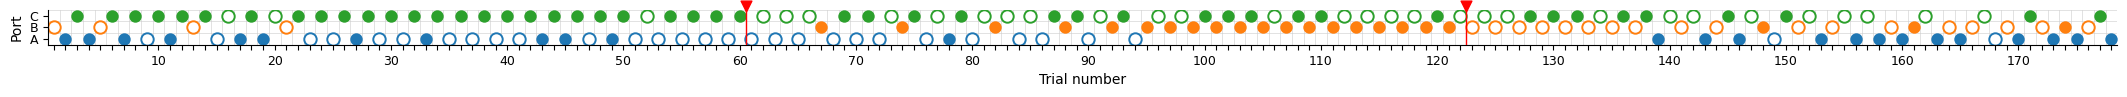

In [2]:
PORT_COLORS = {"A": "tab:blue", "B": "tab:orange", "C": "tab:green"}


def plot_port_values(ax, values, title, session=session):
    """Plot each port's value at the start of every trial (from port_values_per_trial).
    Dots show port visits (filled if rewarded) and red lines show block changes."""
    # Loop through ports to plot each port's values
    for port, color in PORT_COLORS.items():
        ax.plot(values.index, values[port], color=color, label=port)
        visits = values[values["port"] == port]
        ax.scatter(visits.index, visits[port], color=color, s=12, zorder=3,
                   facecolors=[color if reward else "white" for reward in visits["reward"]])
    draw_blocks(ax, session, show_probabilities=False)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_ylim(0, 1)
    ax.axhline(0.5, color="gray", linestyle="--", alpha=0.3)


def plot_port_choices(ports, rewards, session):
    """Plot the rat's port choices on a grid (1 row per port, 1 column per trial).
    Circles show port visits (filled if rewarded) and red lines show block changes."""
    n_trials = len(ports)
    cell = 0.15  # inches per grid cell
    fig, ax = plt.subplots(figsize=(n_trials * cell, 24 * cell))

    port_rows = {"A": 1, "B": 2, "C": 3}
    # Loop through trials to plot a circle for each port visit
    for trial, (port, reward) in enumerate(zip(ports, rewards), start=1):
        color = PORT_COLORS[port]
        if reward:
            ax.scatter(trial, port_rows[port], color=color, s=80, zorder=2, linewidths=0)
        else:
            ax.scatter(trial, port_rows[port], facecolors="white", edgecolors=color, s=80, linewidths=1.4, zorder=2)

    # Loop through block changes to plot a line for each
    for block_start in np.cumsum(session["trials_per_block"])[:-1] + 1:
        ax.axvline(block_start - 0.5, color="red", linewidth=1.0, zorder=3)
        ax.scatter(block_start - 0.5, 3.8, marker="v", color="red", s=60, zorder=4, clip_on=False)

    # Grid (minor ticks at cell edges so dots sit centered)
    ax.set_xticks(range(1, n_trials + 1))
    ax.set_yticks([1, 2, 3])
    ax.set_xticklabels(range(1, n_trials + 1), fontsize=9)
    ax.set_yticklabels(["A", "B", "C"], fontsize=9)
    ax.set_xticks(np.arange(0.5, n_trials + 1.5), minor=True)
    ax.set_yticks([0.5, 1.5, 2.5, 3.5], minor=True)
    ax.set_xlim(0.5, n_trials + 0.5)
    ax.set_ylim(0.5, 3.5)
    ax.set_aspect("equal")
    ax.grid(True, which="minor", linestyle="-", linewidth=0.4, color="#cccccc", zorder=0)
    ax.tick_params(which="minor", length=0)
    ax.set_axisbelow(True)

    # Loop through tick labels to only show every 10th trial num
    for i, label in enumerate(ax.xaxis.get_ticklabels()):
        label.set_visible((i + 1) % 10 == 0)
    ax.set_xlabel("Trial number", fontsize=10)
    ax.set_ylabel("Port", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    return fig, ax


fig, ax = plot_port_choices(ports, rewards, session)
plt.show()

## 1. Fit to rewards vs fit to choices

Each model's free parameters can be fit in 2 ways:

**fit_rewards()** fits model parameters to maximize the likelihood of the observed REWARDS.
"Given the model's port values, how likely was the rat to get rewarded (or not) on each trial?"
This finds the best learner for the task, which isn't necessarily what the rat is doing.

**fit_choices()** fits model parameters + softmax inverse temperature (beta) to maximize the likelihood of the rat's port CHOICES.
"Given the model's port values, how likely was the rat to pick the port it picked?" (out of the 2 ports it didn't just visit).
This is what we use to model the rat.

In [3]:
# Fit each model to rewards
rw_reward_fit = RescorlaWagner.fit_rewards(ports, rewards)
bayes_reward_fit = BayesianPortLearner.fit_rewards(ports, rewards)
hidden_state_reward_fit = HiddenStatePortLearner.fit_rewards(ports, rewards)

# Fit each model to choices
rw_choice_fit = RescorlaWagner.fit_choices(ports, rewards)
bayes_choice_fit = BayesianPortLearner.fit_choices(ports, rewards)
hidden_state_choice_fit = HiddenStatePortLearner.fit_choices(ports, rewards)

# Put the fits in dicts so we can loop through them for the tables and plots below
reward_fits = {"Rescorla-Wagner": rw_reward_fit, "Bayesian": bayes_reward_fit, "Hidden State": hidden_state_reward_fit}
choice_fits = {"Rescorla-Wagner": rw_choice_fit, "Bayesian": bayes_choice_fit, "Hidden State": hidden_state_choice_fit}


def parameters(fit):
    """Get a fitted model's parameters as text (for Bayesian, prior_strength = prior_a = prior_b)."""
    if isinstance(fit, BayesianPortLearner):
        return f"prior_strength = {fit.prior_a:.3f}, decay = {fit.decay:.3f}"
    return f"alpha = {fit.alpha:.3f}, decay = {fit.decay:.3f}"


# Print reward fit stats (loop through models to make 1 row each)
print("Fit to rewards (2 parameters each)")
display(pd.DataFrame({name: {"parameters": parameters(fit), "reward NLL": round(fit.reward_nll_, 1),
                             "BIC": round(fit.reward_bic_, 1)}
                      for name, fit in reward_fits.items()}).T.sort_values("BIC"))

# Print choice fit stats (loop through models to make 1 row each)
print("Fit to choices (3 parameters each)")
display(pd.DataFrame({name: {"parameters": parameters(fit), "beta (inverse temp)": round(fit.beta, 3),
                             "choice NLL": round(fit.choice_nll_, 1), "BIC": round(fit.choice_bic_, 1)}
                      for name, fit in choice_fits.items()}).T.sort_values("BIC"))

Fit to rewards (2 parameters each)


,parameters,reward NLL,BIC
Hidden State,"alpha = 1.000, decay = 0.017",95.2,200.7
Bayesian,"prior_strength = 0.531, decay = 0.102",104.1,218.7
Rescorla-Wagner,"alpha = 0.219, decay = 0.041",105.4,221.2


Fit to choices (3 parameters each)


,parameters,beta (inverse temp),choice NLL,BIC
Bayesian,"prior_strength = 0.686, decay = 0.003",5.231,72.3,160.1
Hidden State,"alpha = 1.000, decay = 0.000",3.232,77.0,169.4
Rescorla-Wagner,"alpha = 0.067, decay = 0.000",6.537,81.0,177.6


Now let's look at the port values from each best-fit model (reward-fit on the left, choice-fit on the right). Note beta doesn't change a model's port values, so any differences come from the other parameters.

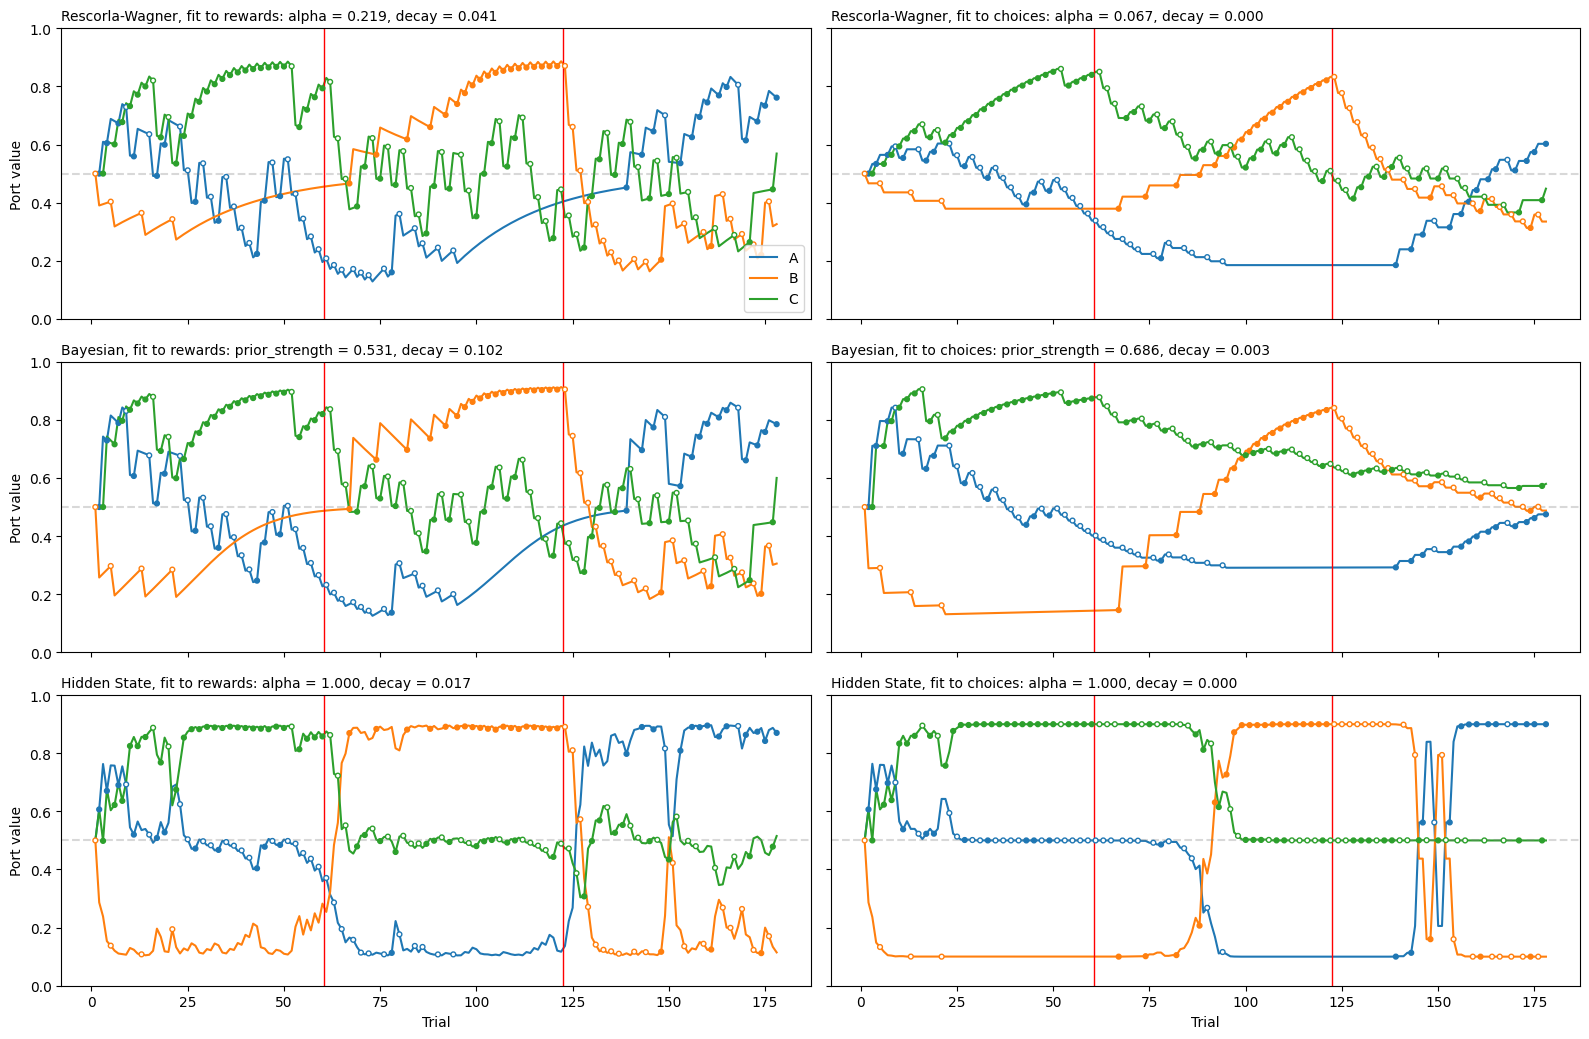

In [4]:
# Plot port values for each model (rows), fit to rewards and choices (columns)
fig, axes = plt.subplots(len(choice_fits), 2, figsize=(16, 3.5 * len(choice_fits)), sharex=True, sharey=True)
# Loop through models (rows), then the reward and choice fits (columns) to plot port values for each
for row, name in zip(axes, choice_fits):
    for ax, fit, how in zip(row, [reward_fits[name], choice_fits[name]], ["fit to rewards", "fit to choices"]):
        plot_port_values(ax, port_values_per_trial(fit, ports, rewards), f"{name}, {how}: {parameters(fit)}")
axes[0, 0].legend(loc="lower right")
# Loop through the left column to label the y axes
for ax in axes[:, 0]:
    ax.set_ylabel("Port value")
# Loop through the bottom row to label the x axes
for ax in axes[-1]:
    ax.set_xlabel("Trial")
plt.tight_layout()
plt.show()

## 2. Cross-evaluation: reward-fit parameters → choice NLL

The reward-fit models learn the port values that best explain the observed rewards. But how well do those values explain the rat's **choices**?

Here we take each reward-fit model, fit **only** beta (inverse temperature) to the choices, and get the choice NLL. This asks: "if the rat learned the best values for the task, how well do they explain what it did?"

Beta is the only free parameter here (k=1), so BIC penalizes it less than the full choice fit (k=3).

In [5]:
def fit_beta(fitted, ports, rewards):
    """Fit only beta (inverse temperature) to choices, keeping the model's other best-fit
    parameters. Returns (beta, choice NLL)."""
    model = copy.deepcopy(fitted)

    def choice_nll(beta):
        model.beta = beta
        return model.choice_nll(ports, rewards)

    result = minimize_scalar(choice_nll, bounds=(0.0, 100.0), method="bounded")
    return result.x, result.fun


# Fit only beta for each reward-fit model
cross_fits = {
    "Rescorla-Wagner": fit_beta(rw_reward_fit, ports, rewards),
    "Bayesian": fit_beta(bayes_reward_fit, ports, rewards),
    "Hidden State": fit_beta(hidden_state_reward_fit, ports, rewards),
}

rows = {}
# Loop through models to make a table comparing the beta-only fit to the full choice fit (1 row per model)
for name, (beta, nll) in cross_fits.items():
    fit = reward_fits[name]
    cross_bic = 1 * np.log(len(rewards)) + 2 * nll  # BIC with k=1 (only beta is free)
    rows[name] = {"reward-fit parameters": parameters(fit), "beta (inverse temp)": round(beta, 3),
                  "choice NLL": round(nll, 1), "BIC (only beta fit)": round(cross_bic, 1),
                  "BIC (full choice fit)": round(choice_fits[name].choice_bic_, 1)}
display(pd.DataFrame(rows).T.sort_values("BIC (only beta fit)"))

,reward-fit parameters,beta (inverse temp),choice NLL,BIC (only beta fit),BIC (full choice fit)
Rescorla-Wagner,"alpha = 0.219, decay = 0.041",2.662,110.2,225.5,177.6
Hidden State,"alpha = 1.000, decay = 0.017",1.505,111.0,227.2,169.4
Bayesian,"prior_strength = 0.531, decay = 0.102",2.107,111.9,229.1,160.1


## 3. Uncertainty in the port values

The Bayesian model has a natural posterior uncertainty (Beta credible intervals from `confidence_interval`), and the Hidden State model has belief-spread uncertainty (how much the possible states disagree about a port's reward probability, from `expected_value_std`).

Here we step through the session trial by trial and get each port's value and uncertainty at the start of every trial. Each figure shows all 3 ports together, then each port on its own so the bands are easier to see.

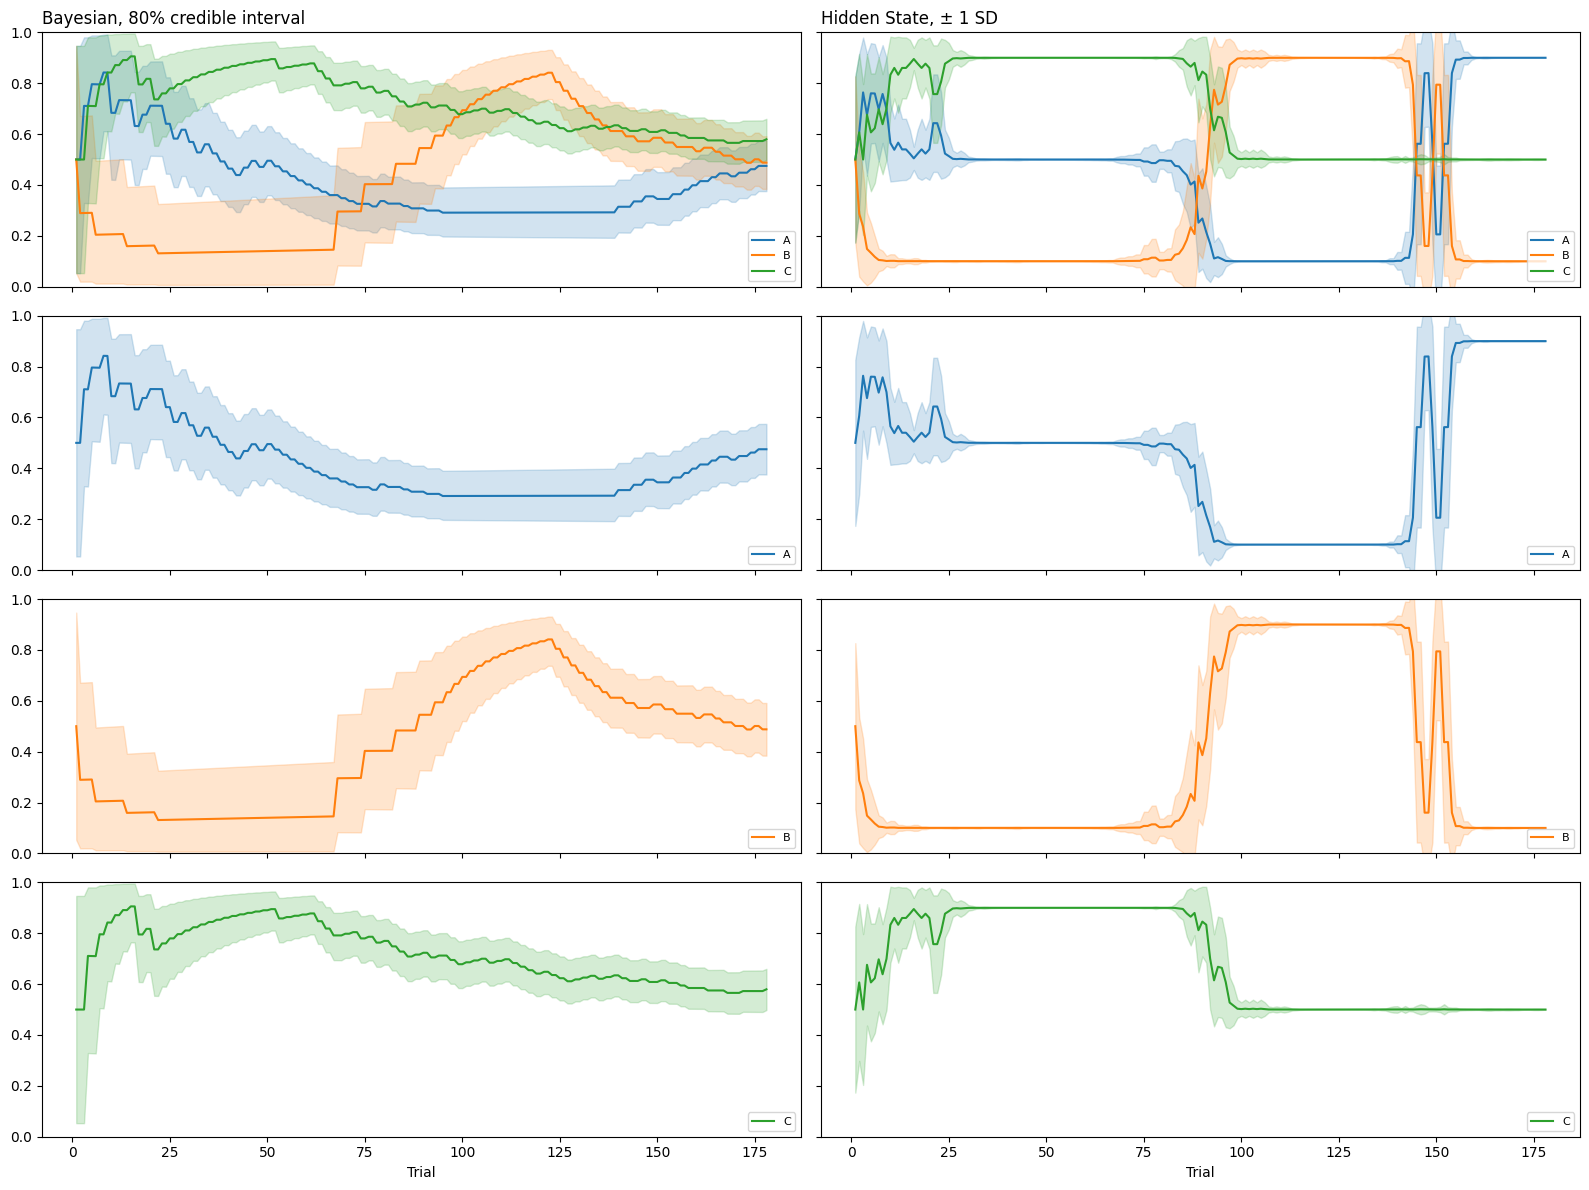

In [6]:
def values_with_uncertainty(fitted, get_bounds):
    """Step a fresh copy of a fitted model through the session trial by trial, and get each port's
    value and (lower, upper) bounds at the start of every trial as {port: (values, lowers, uppers)}."""
    model = copy.deepcopy(fitted)
    model.reset()
    traces = {port: ([], [], []) for port in "ABC"}
    start_port = None
    # Loop through trials to get each port's value and bounds before each update
    for port, reward in zip(ports, rewards):
        # Loop through ports to get each one's value and bounds
        for p in "ABC":
            value = model.expected_value(p)
            lower, upper = get_bounds(model, p)
            # Add the value, lower bound and upper bound to their traces
            for trace, x in zip(traces[p], (value, lower, upper)):
                trace.append(x)
        model.update(port, reward, start_port)
        start_port = port
    return traces


# Get values and uncertainty from the choice-fit Bayesian and Hidden State models
bayes = choice_fits["Bayesian"]
hidden_state = choice_fits["Hidden State"]
uncertainty = {
    "Bayesian, 80% credible interval": values_with_uncertainty(
        bayes, lambda model, p: model.confidence_interval(p, ci=0.8)),
    "Hidden State, ± 1 SD": values_with_uncertainty(
        hidden_state, lambda model, p: (model.expected_value(p) - model.expected_value_std(p),
                                        model.expected_value(p) + model.expected_value_std(p))),
}

# Plot 1 column per model: all ports on top, then 1 port per row (so we can see the bands better)
trial_numbers = np.arange(1, len(rewards) + 1)
fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex=True, sharey=True)
# Loop through models (1 column each)
for column, (title, traces) in zip(axes.T, uncertainty.items()):
    column[0].set_title(title, loc="left")
    # Loop through rows (all ports, then A, B and C), then the ports in each row to plot them
    for row, ports_shown in zip(column, ["ABC", "A", "B", "C"]):
        for p in ports_shown:
            values, lowers, uppers = traces[p]
            row.plot(trial_numbers, values, color=PORT_COLORS[p], label=p)
            row.fill_between(trial_numbers, lowers, uppers, color=PORT_COLORS[p], alpha=0.2)
        row.set_ylim(0, 1)
        row.legend(loc="lower right", fontsize=8)
# Loop through the bottom row to label the x axes
for ax in axes[-1]:
    ax.set_xlabel("Trial")
plt.tight_layout()
plt.show()

## 4. What each parameter does

For each parameter, we keep the other parameters fixed at their best-fit (choice-fit) values and try 3 different values for comparison.

**Rescorla-Wagner**
- **alpha (learning rate)** controls how much a port's Q value is updated based on a new observation
- **decay** controls how much each port's Q value decays back towards the prior (0.5) each trial, modelling forgetting / uncertainty

**Bayesian**
- **prior_strength** sets the effective sample size of the Beta prior (prior_a = prior_b = prior_strength, so all ports start at 0.5). Higher values anchor estimates toward 0.5 and need more port visits to shift (similar to a lower learning rate)
- **decay** shrinks the posterior back toward the prior each trial. Higher decay makes the model forget faster (and keeps credible intervals wider)

**Hidden State**
- **alpha (learning rate)** controls how much the belief over states is updated each trial. alpha=1.0 is a full Bayesian update; lower values make the model slower to shift its belief
- **decay** resets the belief toward uniform each trial. Higher values make the model expect the reward probabilities to be reassigned more often
- **reward_set** is the assumed set of reward probabilities across ports. A tighter spread (e.g. 0.65/0.5/0.35) makes it harder to tell which port has which probability

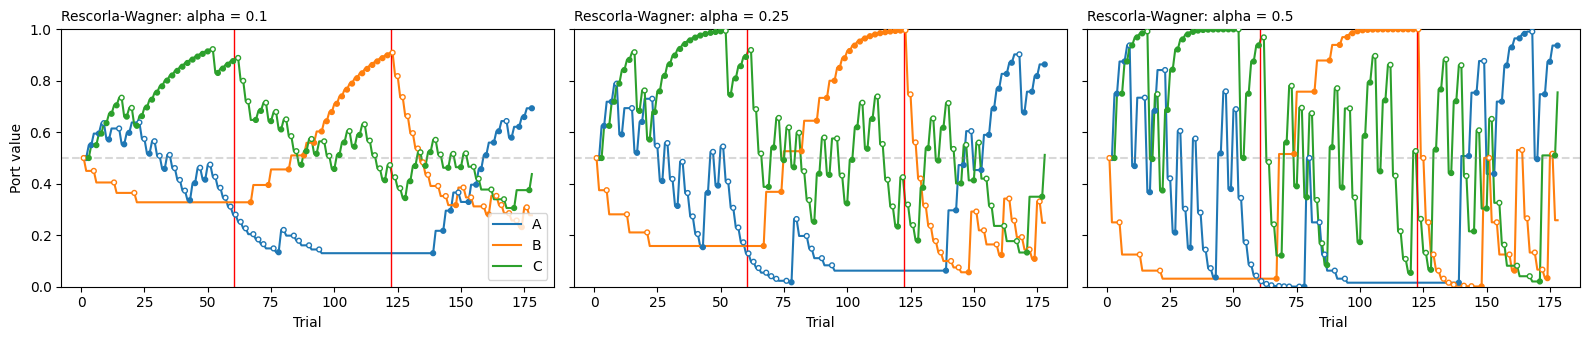

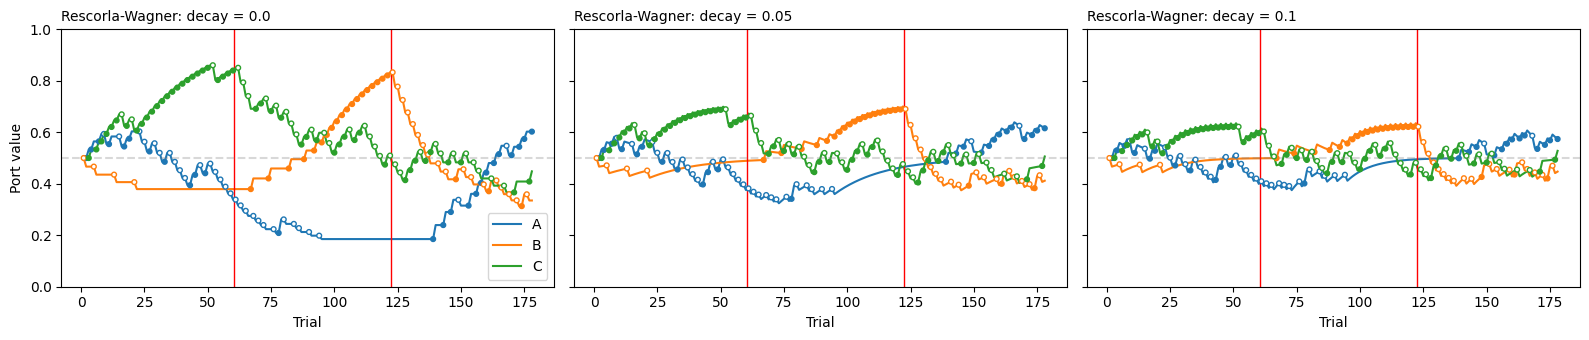

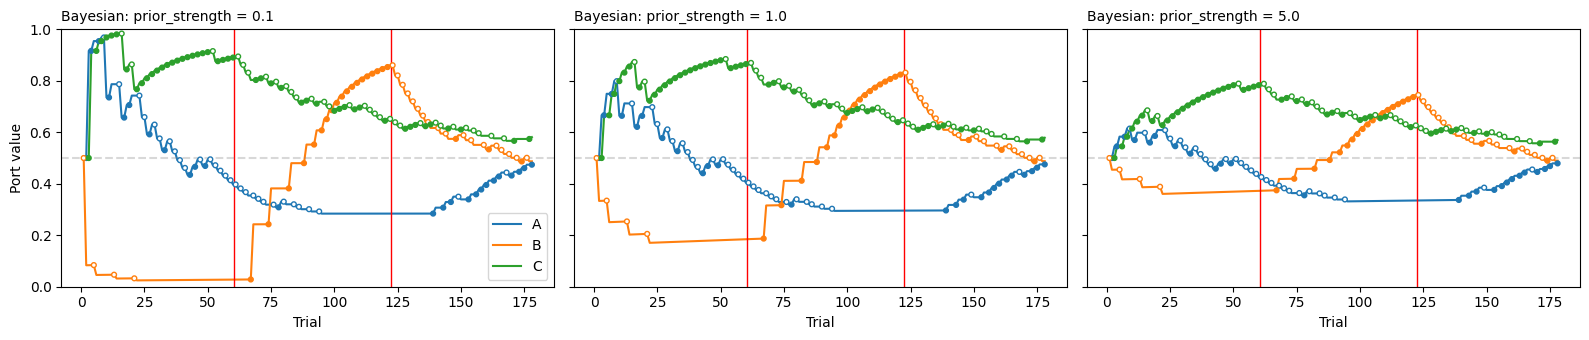

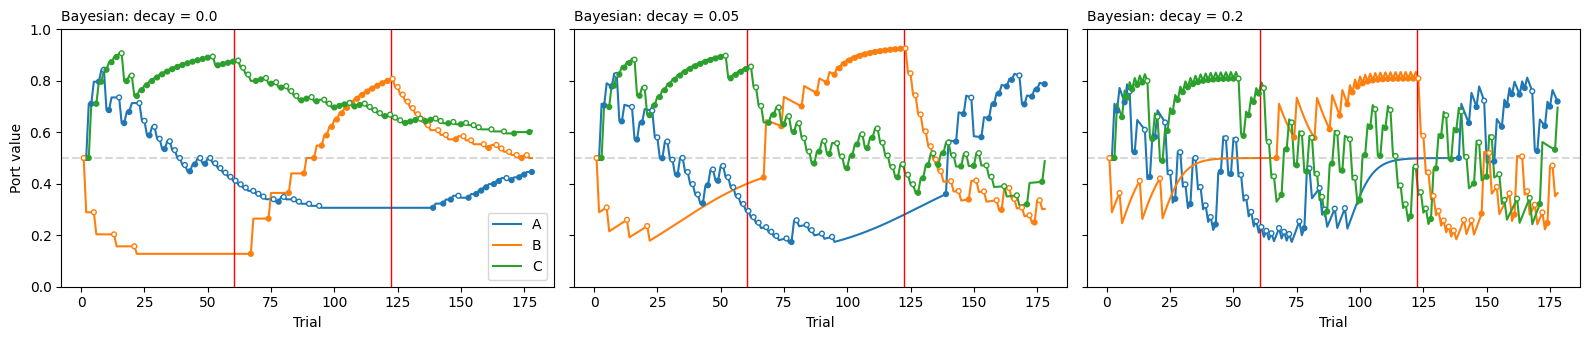

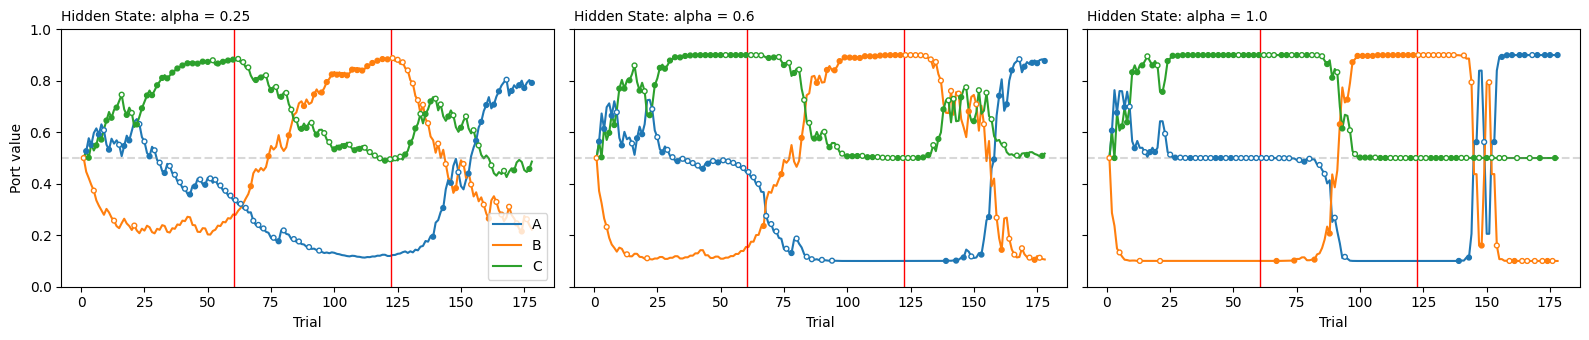

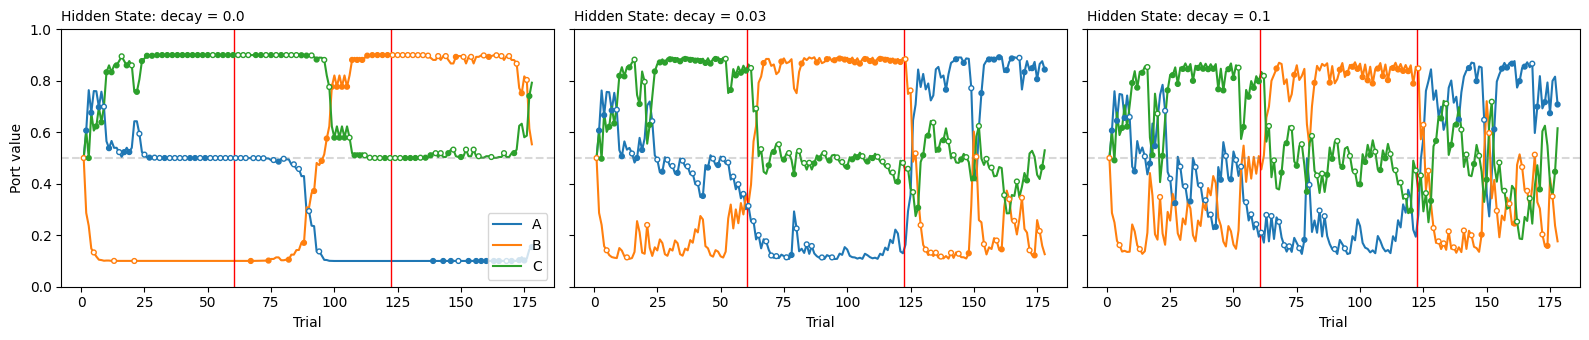

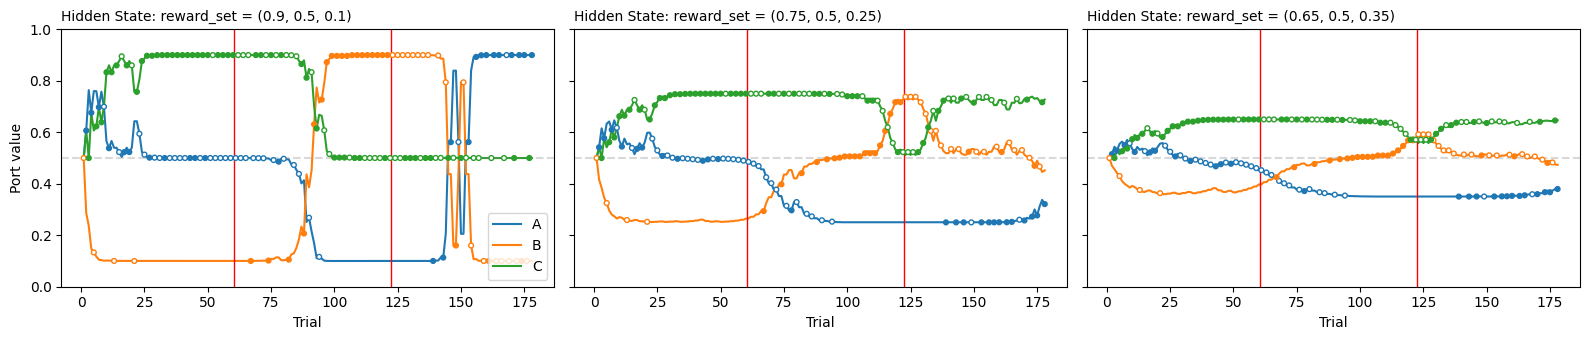

In [7]:
def compare_parameter(make_model, settings, title):
    """Plot port values for a model made with each setting (side by side for comparison)."""
    fig, axes = plt.subplots(1, len(settings), figsize=(16, 3.5), sharey=True)
    # Loop through settings to plot port values for each (side by side)
    for ax, setting in zip(axes, settings):
        plot_port_values(ax, port_values_per_trial(make_model(setting), ports, rewards), f"{title} = {setting}")
        ax.set_xlabel("Trial")
    axes[0].set_ylabel("Port value")
    axes[0].legend(loc="lower right")
    plt.tight_layout()
    plt.show()


## Rescorla-Wagner: look at the effect of learning rate (alpha) and decay
rw = choice_fits["Rescorla-Wagner"]
compare_parameter(lambda alpha: RescorlaWagner(alpha=alpha, decay=rw.decay), [0.1, 0.25, 0.5], "Rescorla-Wagner: alpha")
compare_parameter(lambda decay: RescorlaWagner(alpha=rw.alpha, decay=decay), [0.0, 0.05, 0.1], "Rescorla-Wagner: decay")

## Bayesian: look at the effect of prior strength and decay
compare_parameter(lambda strength: BayesianPortLearner(prior_a=strength, prior_b=strength, decay=bayes.decay),
                  [0.1, 1.0, 5.0], "Bayesian: prior_strength")
compare_parameter(lambda decay: BayesianPortLearner(prior_a=bayes.prior_a, prior_b=bayes.prior_b, decay=decay),
                  [0.0, 0.05, 0.2], "Bayesian: decay")

## Hidden State: look at the effect of learning rate (alpha), decay, and reward set spread
compare_parameter(lambda alpha: HiddenStatePortLearner(alpha=alpha, decay=hidden_state.decay),
                  [0.25, 0.6, 1.0], "Hidden State: alpha")
compare_parameter(lambda decay: HiddenStatePortLearner(alpha=hidden_state.alpha, decay=decay),
                  [0.0, 0.03, 0.1], "Hidden State: decay")
compare_parameter(lambda reward_set: HiddenStatePortLearner(reward_set=reward_set, alpha=hidden_state.alpha,
                                                            decay=hidden_state.decay),
                  [(0.9, 0.5, 0.1), (0.75, 0.5, 0.25), (0.65, 0.5, 0.35)], "Hidden State: reward_set")

## 5. A separate value table for each start port

With `per_start_port=True` (`RescorlaWagner` and `BayesianPortLearner` only), the model keeps a separate table of Q values for each start port (the port the rat just left). So what the rat learns on a trip from A only changes its choices on later trips from A (fully model free). The first trial doesn't start at a port, so its outcome goes in every table that has the reached port as an option.

`port_values_per_trial` then gives:
- **A**, **B**, **C**: the values from the start port's table (the ones the rat chose with). The start port's own column is NaN, since it wasn't an option
- **B from A**, **C from A**, **A from B**, ...: every table's values

The plot below shows every table's values at the start of every trial. Color is the port and line style is the start port (e.g. green dashed is C's value on trips from B), with a dot on the trips that went from that start port to that port (filled if rewarded).

One table:            alpha = 0.067, decay = 0.000, beta (inverse temp) = 6.537, choice NLL = 81.0
Table per start port: alpha = 0.116, decay = 0.000, beta (inverse temp) = 4.901, choice NLL = 95.9


,start port,port,reward,A,B,C,p(A),p(B),p(C),B from A,C from A,A from B,C from B,A from C,B from C
trial,,,,,,,,,,,,,,,
1,None,B,0.0,0.500000,0.500000,0.500000,0.333333,0.333333,0.333333,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
2,B,A,1.0,0.500000,NaN,0.500000,0.500000,NaN,0.500000,0.442064,0.500000,0.500000,0.500000,0.500000,0.442064
3,A,C,1.0,NaN,0.442064,0.500000,NaN,0.429489,0.570511,0.442064,0.500000,0.557936,0.500000,0.500000,0.442064
4,C,A,1.0,0.500000,0.442064,NaN,0.570511,0.429489,NaN,0.442064,0.557936,0.557936,0.500000,0.500000,0.442064
5,A,B,0.0,NaN,0.442064,0.557936,NaN,0.361728,0.638272,0.442064,0.557936,0.557936,0.500000,0.557936,0.442064
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174,A,B,1.0,NaN,0.274934,0.459403,NaN,0.288218,0.711782,0.274934,0.459403,0.655459,0.354291,0.555843,0.302437
175,B,A,1.0,0.655459,NaN,0.354291,0.813965,NaN,0.186035,0.358948,0.459403,0.655459,0.354291,0.555843,0.302437
176,A,B,0.0,NaN,0.358948,0.459403,NaN,0.379349,0.620651,0.358948,0.459403,0.695382,0.354291,0.555843,0.302437


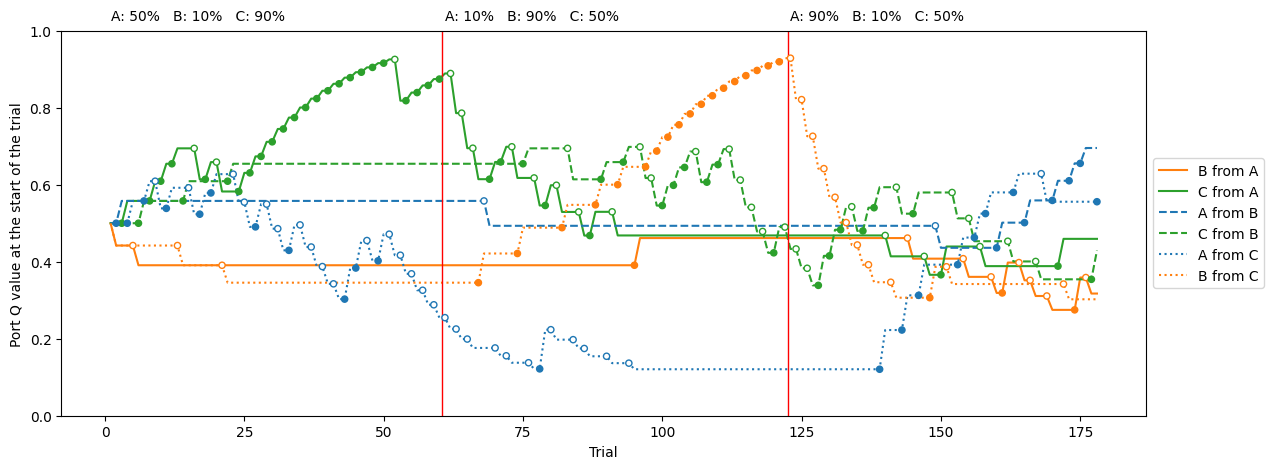

In [8]:
# Fit Rescorla-Wagner to choices again, with a separate table of Q values for each start port
# (this fits its own alpha, decay and beta, so they're different from the one-table fit)
per_start_fit = RescorlaWagner.fit_choices(ports, rewards, per_start_port=True)

# Print the best-fit parameters and choice NLL for each
one_table_fit = choice_fits["Rescorla-Wagner"]
print(f"One table:            alpha = {one_table_fit.alpha:.3f}, decay = {one_table_fit.decay:.3f}, "
      f"beta (inverse temp) = {one_table_fit.beta:.3f}, choice NLL = {one_table_fit.choice_nll_:.1f}")
print(f"Table per start port: alpha = {per_start_fit.alpha:.3f}, decay = {per_start_fit.decay:.3f}, "
      f"beta (inverse temp) = {per_start_fit.beta:.3f}, choice NLL = {per_start_fit.choice_nll_:.1f}")

per_start_values = port_values_per_trial(per_start_fit, ports, rewards)
display(per_start_values)

# Every table's values on one graph: color is the port, line style is the start port
START_STYLES = {"A": "-", "B": "--", "C": ":"}
fig, ax = plt.subplots(figsize=(14, 5))
# Loop through start ports (line styles) to plot each table's values
for start_name, style in START_STYLES.items():
    trips = per_start_values[per_start_values["start port"] == start_name]
    # Loop through ports (colors) to plot this start port's table (a table never has its own start port)
    for name, color in PORT_COLORS.items():
        if name == start_name:
            continue
        ax.plot(per_start_values.index, per_start_values[f"{name} from {start_name}"], color=color,
                linestyle=style, label=f"{name} from {start_name}")
        visits = trips[trips["port"] == name]
        ax.scatter(visits.index, visits[f"{name} from {start_name}"], color=color, s=20, zorder=3,
                   facecolors=[color if reward else "white" for reward in visits["reward"]])
draw_blocks(ax, session)

ax.set_xlabel("Trial")
ax.set_ylabel("Port Q value at the start of the trial")
ax.set_ylim(0, 1)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

## 6. Other useful methods

Beyond `fit_rewards()`, `fit_choices()` and `port_values_per_trial()`, each model has methods for stepping through trials, getting current port values and choice probabilities, and looking at the full history. These work the same way across all models (with some model-specific extras).

Note ports can be given as 1/2/3 or A/B/C, but always come back as 1/2/3.

In [9]:
## update() - single-step learning
# Instead of calling learn() on a full session, you can step through trials one at a time.
# update() returns the reward prediction error (RW) or surprise (Bayesian / Hidden State)
rw = RescorlaWagner(alpha=0.3, decay=0.05)
# Loop through the first 5 trials to update one at a time
for i in range(5):
    prediction_error = rw.update(ports[i], rewards[i])
    print(f"Trial {i + 1}: port = {ports[i]}, reward = {rewards[i]}, prediction error = {prediction_error:+.3f}, "
          f"Q = {rw.get_values()}")

## get_values() - snapshot of current port values as {port: value}
print("\n--- get_values() ---")
bayes = BayesianPortLearner(prior_a=1.0, prior_b=1.0, decay=0.05)
bayes.learn(ports[:20], rewards[:20])
hidden_state = HiddenStatePortLearner(reward_set=(0.9, 0.5, 0.1), decay=0.03)
hidden_state.learn(ports[:20], rewards[:20])
print(f"Rescorla-Wagner Q values:  {rw.get_values()}")
print(f"Bayesian posterior means:  {bayes.get_values()}")
print(f"Hidden State values:       {hidden_state.get_values()}")

## choice_probabilities() - softmax over current port values as {port: probability}
# Higher beta (inverse temperature) is more exploitative (closer to always picking the best port)
print("\n--- choice_probabilities() ---")
print(f"beta = 1:                 {rw.choice_probabilities()}")
rw_greedy = RescorlaWagner(alpha=0.3, beta=10.0, decay=0.05)
rw_greedy.learn(ports[:20], rewards[:20])
print(f"beta = 10:                {rw_greedy.choice_probabilities()}")
# You can also restrict to a subset of available ports (e.g. the 2 the rat didn't just visit)
print(f"beta = 10, A vs C only:   {rw_greedy.choice_probabilities(available_ports=['A', 'C'])}")

## reset() - clear learned values and history (keeping the same parameters)
print("\n--- reset() ---")
print(f"Before reset: {rw.get_values()}")
rw.reset()
print(f"After reset:  {rw.get_values()}")

Trial 1: port = B, reward = 0.0, prediction error = -0.500, Q = {1: 0.5, 2: np.float64(0.35), 3: 0.5}
Trial 2: port = A, reward = 1.0, prediction error = +0.500, Q = {1: np.float64(0.65), 2: np.float64(0.3575), 3: 0.5}
Trial 3: port = C, reward = 1.0, prediction error = +0.500, Q = {1: np.float64(0.6425), 2: np.float64(0.364625), 3: np.float64(0.65)}
Trial 4: port = A, reward = 1.0, prediction error = +0.365, Q = {1: np.float64(0.7447625), 2: np.float64(0.37139374999999997), 3: np.float64(0.6425)}
Trial 5: port = B, reward = 0.0, prediction error = -0.378, Q = {1: np.float64(0.732524375), 2: np.float64(0.26447684375), 3: np.float64(0.6353749999999999)}

--- get_values() ---
Rescorla-Wagner Q values:  {1: np.float64(0.732524375), 2: np.float64(0.26447684375), 3: np.float64(0.6353749999999999)}
Bayesian posterior means:  {1: 0.6714881986266795, 2: 0.282567123429426, 3: 0.6551023863927401}
Hidden State values:       {1: 0.7043031136599271, 2: 0.23988329064929312, 3: 0.5558135956907798}

-

In [10]:
## Bayesian-specific: get_posteriors() and confidence_interval()
bayes = BayesianPortLearner(prior_a=1.0, prior_b=1.0, decay=0.05)
bayes.learn(ports, rewards)

# get_posteriors() returns the raw Beta(a, b) parameters for each port
print("--- get_posteriors() ---")
# Loop through ports to print each one's posterior
for port, post in bayes.get_posteriors().items():
    print(f"  Port {port}: Beta(a = {post['a']:.2f}, b = {post['b']:.2f}), mean = {post['a'] / (post['a'] + post['b']):.3f}")

# confidence_interval() returns a credible interval for a port's reward probability (default is 95%)
print("\n--- confidence_interval() ---")
# Loop through ports to print each one's credible intervals
for port in "ABC":
    low_95, high_95 = bayes.confidence_interval(port, ci=0.95)
    low_80, high_80 = bayes.confidence_interval(port, ci=0.80)
    print(f"  Port {port}: 95% CI = [{low_95:.3f}, {high_95:.3f}], 80% CI = [{low_80:.3f}, {high_80:.3f}]")

## Hidden State-specific: get_state_posteriors() and get_stds()
hidden_state = HiddenStatePortLearner(reward_set=(0.9, 0.5, 0.1), decay=0.03)
hidden_state.learn(ports, rewards)

# get_state_posteriors() shows the model's belief over all possible port-to-probability assignments
print("\n--- get_state_posteriors() ---")
# Loop through states to print the belief in each
for state in hidden_state.get_state_posteriors():
    assignment = ", ".join(f"{name} = {state['assignment'][port]}" for name, port in zip("ABC", (1, 2, 3)))
    print(f"  [{assignment}]  P = {state['probability']:.4f}  {'█' * int(state['probability'] * 50)}")

# get_stds() returns the SD of expected reward for each port (high SD = unsure which probability this port has)
print("\n--- get_stds() ---")
# Loop through ports to print each one's value and SD
for port, sd in hidden_state.get_stds().items():
    print(f"  Port {port}: value = {hidden_state.expected_value(port):.3f} ± {sd:.3f}")

--- get_posteriors() ---
  Port 1: Beta(a = 7.13, b = 1.91), mean = 0.788
  Port 2: Beta(a = 2.90, b = 6.24), mean = 0.318
  Port 3: Beta(a = 3.81, b = 3.99), mean = 0.489

--- confidence_interval() ---
  Port A: 95% CI = [0.488, 0.972], 80% CI = [0.608, 0.938]
  Port B: 95% CI = [0.078, 0.632], 80% CI = [0.136, 0.519]
  Port C: 95% CI = [0.172, 0.811], 80% CI = [0.266, 0.714]

--- get_state_posteriors() ---
  [A = 0.9, B = 0.5, C = 0.1]  P = 0.0346  █
  [A = 0.9, B = 0.1, C = 0.5]  P = 0.9045  █████████████████████████████████████████████
  [A = 0.5, B = 0.9, C = 0.1]  P = 0.0043  
  [A = 0.5, B = 0.1, C = 0.9]  P = 0.0523  ██
  [A = 0.1, B = 0.9, C = 0.5]  P = 0.0014  
  [A = 0.1, B = 0.5, C = 0.9]  P = 0.0030  

--- get_stds() ---
  Port 1: value = 0.874 ± 0.106
  Port 2: value = 0.120 ± 0.096
  Port 3: value = 0.507 ± 0.123


In [11]:
## get_history() - full trial-by-trial record
# All models store a full history when you call learn() or update().
# Each entry is a dict with the trial's port, reward, and model-specific stuff
rw = RescorlaWagner(alpha=0.3, decay=0.05)
rw.learn(ports[:3], rewards[:3])
print("--- Rescorla-Wagner: prediction error and Q values ---")
# Loop through trials to print each history entry
for step in rw.get_history():
    print(f"  {step}")

bayes = BayesianPortLearner(prior_a=1.0, prior_b=1.0, decay=0.05)
bayes.learn(ports[:3], rewards[:3])
print("\n--- Bayesian: surprise and posteriors ---")
# Loop through trials to print each history entry
for step in bayes.get_history():
    print(f"  {step}")

hidden_state = HiddenStatePortLearner(reward_set=(0.9, 0.5, 0.1), decay=0.03)
hidden_state.learn(ports[:3], rewards[:3])
print("\n--- Hidden State: surprise, belief over the 6 states, values and their SDs ---")
# Loop through trials to print each history entry
for step in hidden_state.get_history():
    print(f"  {step}")

--- Rescorla-Wagner: prediction error and Q values ---
  {'port': 2, 'reward': np.float64(0.0), 'prediction_error': np.float64(-0.5), 'Q': {1: 0.5, 2: np.float64(0.35), 3: 0.5}}
  {'port': 1, 'reward': np.float64(1.0), 'prediction_error': np.float64(0.5), 'Q': {1: np.float64(0.65), 2: np.float64(0.3575), 3: 0.5}}
  {'port': 3, 'reward': np.float64(1.0), 'prediction_error': np.float64(0.5), 'Q': {1: np.float64(0.6425), 2: np.float64(0.364625), 3: np.float64(0.65)}}

--- Bayesian: surprise and posteriors ---
  {'port': 2, 'reward': np.float64(0.0), 'surprise': np.float64(0.6931471805599453), 'posteriors': {1: {'a': 1.0, 'b': 1.0}, 2: {'a': 1.0, 'b': 2.0}, 3: {'a': 1.0, 'b': 1.0}}}
  {'port': 1, 'reward': np.float64(1.0), 'surprise': np.float64(0.6931471805599453), 'posteriors': {1: {'a': 2.0, 'b': 1.0}, 2: {'a': 1.0, 'b': 1.95}, 3: {'a': 1.0, 'b': 1.0}}}
  {'port': 3, 'reward': np.float64(1.0), 'surprise': np.float64(0.6931471805599453), 'posteriors': {1: {'a': 1.95, 'b': 1.0}, 2: {'a': 

## 7. What happens when the fit goes wrong

All of these models assume the rat chooses ports based on how rewarding they've been. If something else is driving the rat's choices, the fit can go wrong! Here's an example barrier change session (rat IM-1478) where the rat's choices seem to follow path length more than reward.

Signs of a bad fit:
- **beta (inverse temperature) is huge** (e.g. thousands) and the learning rate (or decay) is ~0. The port values barely move from 0.5, and the huge beta blows up the tiny differences between them. These values don't really mean anything!
- **Choice NLL per trial is close to chance.** Picking randomly between 2 ports gives ln(2) ≈ 0.69 per trial.

185 trials (barrier change session)


,parameters,beta (inverse temp),choice NLL per trial,chance (ln 2)
Rescorla-Wagner,"alpha = 0.000, decay = 0.046",1864.4,0.664,0.693
Bayesian,"prior_strength = 321943.326, decay = 0.046",90656.0,0.664,0.693
Hidden State,"alpha = 0.000, decay = 0.046",12806.6,0.664,0.693


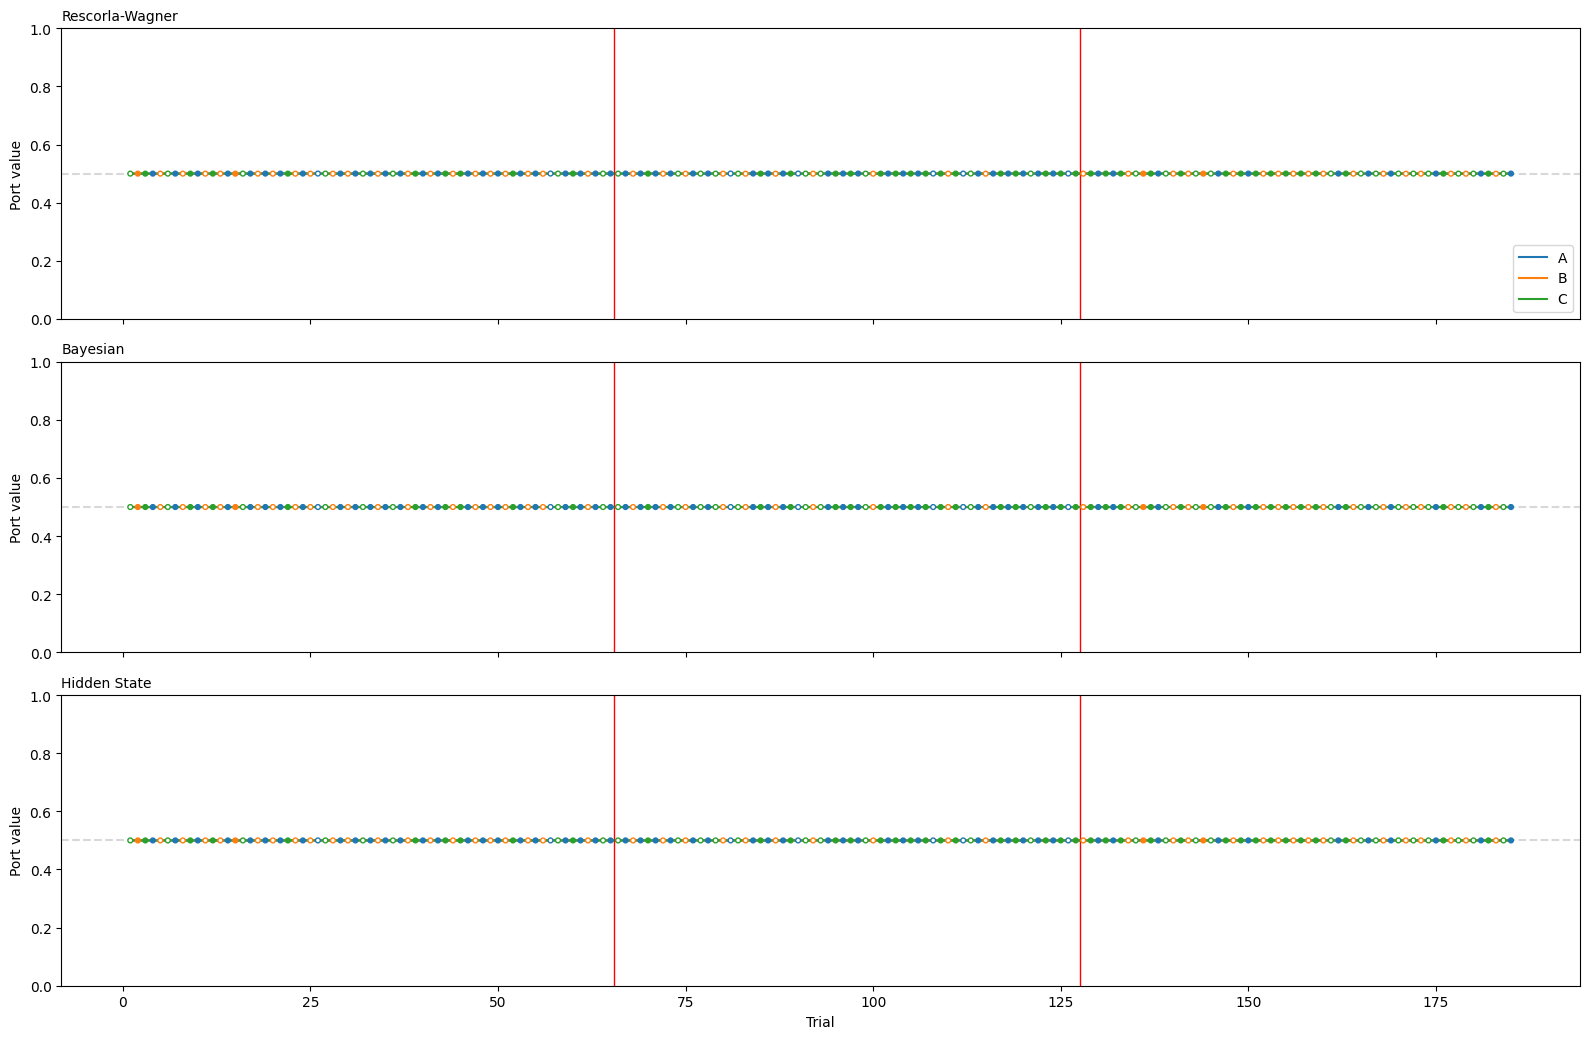

In [12]:
# Load the example "bad" session
bad_session = load_session("example_data/IM-1478_20220719_ep0_14fc3ff2.csv")
bad_ports, bad_rewards = bad_session["ports"], bad_session["rewards"]
print(f"{len(bad_ports)} trials ({bad_session['session_type']} change session)")

# Fit each model to choices
bad_rw_fit = RescorlaWagner.fit_choices(bad_ports, bad_rewards)
bad_bayes_fit = BayesianPortLearner.fit_choices(bad_ports, bad_rewards)
bad_hidden_state_fit = HiddenStatePortLearner.fit_choices(bad_ports, bad_rewards)
bad_fits = {"Rescorla-Wagner": bad_rw_fit, "Bayesian": bad_bayes_fit, "Hidden State": bad_hidden_state_fit}

# Print fit stats (loop through models to make 1 row each)
display(pd.DataFrame({name: {"parameters": parameters(fit), "beta (inverse temp)": round(fit.beta, 1),
                             "choice NLL per trial": round(fit.choice_nll_ / len(bad_ports), 3),
                             "chance (ln 2)": round(np.log(2), 3)}
                      for name, fit in bad_fits.items()}).T)

# Plot port values from each model
fig, axes = plt.subplots(len(bad_fits), 1, figsize=(16, 3.5 * len(bad_fits)), sharex=True)
# Loop through models to plot port values for each (1 panel per model)
for ax, (name, fit) in zip(axes, bad_fits.items()):
    plot_port_values(ax, port_values_per_trial(fit, bad_ports, bad_rewards), name, session=bad_session)
    ax.set_ylabel("Port value")
axes[0].legend(loc="lower right")
axes[-1].set_xlabel("Trial")
plt.tight_layout()
plt.show()

So what is driving the rat's choices? On each trial the rat picks between the 2 ports it didn't just visit. Let's check how often it picked the port with the shorter path (from the port it just left, in that block's maze), vs how often it picked the port with the higher reward probability.

In [13]:
from src.hexmaze import get_reward_path_lengths

# Get path lengths between each pair of ports for each block's maze (loop through blocks; get_reward_path_lengths returns [AB, AC, BC])
path_lengths = [dict(zip(["AB", "AC", "BC"], get_reward_path_lengths(maze))) for maze in bad_session["mazes"]]
# Get the block for each trial
block_of_trial = np.repeat(np.arange(len(bad_session["mazes"])), bad_session["trials_per_block"])

chose_shorter, chose_more_rewarding = [], []
# Loop through trials (after the first) to check which port the rat picked
for trial in range(1, len(bad_ports)):
    start, chosen = bad_ports[trial - 1], bad_ports[trial]
    other = ({"A", "B", "C"} - {start, chosen}).pop()
    block = block_of_trial[trial]

    # Did the rat pick the shorter path? (only count trials where the 2 paths are different lengths)
    chosen_length = path_lengths[block]["".join(sorted(start + chosen))]
    other_length = path_lengths[block]["".join(sorted(start + other))]
    if chosen_length != other_length:
        chose_shorter.append(chosen_length < other_length)

    # Did the rat pick the port with higher reward probability? (reward_probs are [p(A), p(B), p(C)])
    reward_probs = dict(zip("ABC", bad_session["reward_probs"][block]))
    if reward_probs[chosen] != reward_probs[other]:
        chose_more_rewarding.append(reward_probs[chosen] > reward_probs[other])

print(f"Chose the port with the shorter path on {np.mean(chose_shorter):.0%} of trials "
      f"(of the {len(chose_shorter)} trials where the 2 paths are different lengths)")
print(f"Chose the port with the higher reward probability on {np.mean(chose_more_rewarding):.0%} of trials "
      f"(of the {len(chose_more_rewarding)} trials where the 2 ports have different reward probabilities)")

Chose the port with the shorter path on 75% of trials (of the 147 trials where the 2 paths are different lengths)
Chose the port with the higher reward probability on 57% of trials (of the 184 trials where the 2 ports have different reward probabilities)


If the port value models don't explain a session well, check what else might be driving the rat's choices (like path length here) before interpreting the fitted parameters or port values. The hex value learners (see [Hex Value Learning](50_Hex_Value_Learning.ipynb)) learn values along the paths the rat runs, so they can capture choices driven by the maze.